In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
DATA_DIR = Path("D:/rat_decision_project_/data/crcns_pfc-1_data")
print(DATA_DIR.exists())

True


In [3]:
rat_folders = [p for p in DATA_DIR.iterdir() if p.is_dir()]

for p in rat_folders:
    print(p.name)

CR12B
CR17B
CR20B
CR21A
CR24A
miscellaneous
YT6A


In [4]:
mpfc_rats = [
    p for p in rat_folders
    if p.name not in ["CR12B", "CR17B", "miscellaneous"]
]

for p in mpfc_rats:
    print(p.name)

CR20B
CR21A
CR24A
YT6A


In [5]:
candidate_sessions = []

for rat in mpfc_rats:
    for session in rat.iterdir():

        if not session.is_dir():
            continue

        kkp_dir = session / "klusters0"

        if kkp_dir.exists():
            kkp_files = list(kkp_dir.glob("*.kkp"))

            if len(kkp_files) > 0:
                candidate_sessions.append(session)

print("Number of candidate sessions:", len(candidate_sessions))

Number of candidate sessions: 29


In [6]:
for session in candidate_sessions[:10]:
    print(session)

D:\rat_decision_project_\data\crcns_pfc-1_data\CR20B\CR20B_120531_001_behaving
D:\rat_decision_project_\data\crcns_pfc-1_data\CR20B\CR20B_120602_001_behaving
D:\rat_decision_project_\data\crcns_pfc-1_data\CR20B\CR20B_120603_001_behaving
D:\rat_decision_project_\data\crcns_pfc-1_data\CR20B\CR20B_120604_001_behaving
D:\rat_decision_project_\data\crcns_pfc-1_data\CR20B\CR20B_120605_001_behaving
D:\rat_decision_project_\data\crcns_pfc-1_data\CR20B\CR20B_120606_004_behaving
D:\rat_decision_project_\data\crcns_pfc-1_data\CR20B\CR20B_120609_001_behaving
D:\rat_decision_project_\data\crcns_pfc-1_data\CR20B\CR20B_120612_001_behaving
D:\rat_decision_project_\data\crcns_pfc-1_data\CR21A\CR21A_120503_004_behaving
D:\rat_decision_project_\data\crcns_pfc-1_data\CR21A\CR21A_120504_004_behaving


In [7]:
session = candidate_sessions[0]

print("Selected session:")
print(session)

Selected session:
D:\rat_decision_project_\data\crcns_pfc-1_data\CR20B\CR20B_120531_001_behaving


In [8]:
trials_info = pd.read_csv(
    session / "trials_info",
    index_col=0
)

trial_timings = pd.read_csv(
    session / "trial_timings",
    index_col=0
)

trials = trial_timings.join(trials_info)

In [9]:
trials.shape

(352, 12)

In [10]:
trials.head()

,choice_made,cpoke_start,cpoke_stop,stim_onset,is_munged,correct_side,stim_number,nonrandom,outcome,go_or_nogo,block,stim_name
3,238.074050,237.264617,237.588191,237.523909,False,left,3,1,hit,go,1,le_lc_go
4,250.086150,249.086196,249.487838,249.413257,False,left,3,1,hit,go,1,le_lc_go
5,256.169274,255.248223,255.625775,255.586242,False,left,3,1,hit,go,1,le_lc_go
6,264.177063,263.206840,263.586723,263.531909,False,left,3,1,hit,go,1,le_lc_go
7,271.603650,270.693224,270.998028,270.956502,False,left,3,1,hit,go,1,le_lc_go


In [11]:
trials.columns

Index(['choice_made', 'cpoke_start', 'cpoke_stop', 'stim_onset', 'is_munged',
       'correct_side', 'stim_number', 'nonrandom', 'outcome', 'go_or_nogo',
       'block', 'stim_name'],
      dtype='str')

In [12]:
rat_folders = sorted([
    p for p in DATA_DIR.iterdir()
    if p.is_dir() and p.name != "miscellaneous"
])

print("Number of rats:", len(rat_folders))
print("Rats:")
print(rat)
for rat in rat_folders:
    print(" -", rat.name)

Number of rats: 6
Rats:
D:\rat_decision_project_\data\crcns_pfc-1_data\YT6A
 - CR12B
 - CR17B
 - CR20B
 - CR21A
 - CR24A
 - YT6A


In [13]:
rat.name

'YT6A'

In [14]:
sessions_by_rat = {}

for rat in rat_folders:

    sessions = sorted([
        s for s in rat.iterdir()
        if s.is_dir() and (s / "trials_info").exists()
    ])

    sessions_by_rat[rat.name] = sessions

    print(f"{rat.name}: {len(sessions)} sessions")



CR12B: 14 sessions
CR17B: 9 sessions
CR20B: 9 sessions
CR21A: 9 sessions
CR24A: 12 sessions
YT6A: 2 sessions


In [15]:
for x in rat.iterdir():
     print(x)

D:\rat_decision_project_\data\crcns_pfc-1_data\YT6A\YT6A_120201_behaving
D:\rat_decision_project_\data\crcns_pfc-1_data\YT6A\YT6A_120202_behaving


In [16]:
total_sessions = sum(
    len(sessions)
    for sessions in sessions_by_rat.values()
)

print("Total number of sessions:", total_sessions)

Total number of sessions: 55


In [17]:
session_info = []

for rat_name, sessions in sessions_by_rat.items():

    for session in sessions:

        trials = pd.read_csv(
            session / "trials_info",
            index_col=0
        )

        session_info.append({
            "rat": rat_name,
            "session": session.name,
            "n_trials": len(trials)
        })

session_df = pd.DataFrame(session_info)

session_df

,rat,session,n_trials
0,CR12B,CR12B_110421_001_behaving,600
1,CR12B,CR12B_110422_001_behaving,600
2,CR12B,CR12B_110423_001_behaving,600
3,CR12B,CR12B_110426_001_behaving,1200
4,CR12B,CR12B_110428_001_behaving,600
5,CR12B,CR12B_110429_001_behaving,900
6,CR12B,CR12B_110503_001_behaving,600
7,CR12B,CR12B_110504_001_behaving,600
8,CR12B,CR12B_110505_001_behaving,900
9,CR12B,CR12B_110507_001_behaving,600


In [18]:
session_df.sort_values(
    "n_trials",
    ascending=False
)

,rat,session,n_trials
20,CR17B,CR17B_110805_001_behaving,1600
44,CR24A,CR24A_121022_001_behaving,1600
42,CR24A,CR24A_121019_001_behaving,1600
52,CR24A,CR24A_121101_001_behaving,1600
46,CR24A,CR24A_121024_001_behaving,1600
43,CR24A,CR24A_121021_001_behaving,1600
45,CR24A,CR24A_121023_001_behaving,1440
47,CR24A,CR24A_121026_001_behaving,1200
49,CR24A,CR24A_121029_001_behaving,1200
22,CR17B,CR17B_110808_001_behaving,1200


In [19]:
summary_by_rat = (
    session_df
    .groupby("rat")
    .agg(
        n_sessions=("session", "count"),
        n_trials=("n_trials", "sum")
    )
    .reset_index()
)

summary_by_rat

,rat,n_sessions,n_trials
0,CR12B,14,10500
1,CR17B,9,9700
2,CR20B,9,8640
3,CR21A,9,8640
4,CR24A,12,15680
5,YT6A,2,2010


In [20]:
import pickle
import pandas as pd

from pandas.core.indexes.base import Index, _new_Index
from pandas.core.indexes.multi import MultiIndex


class LegacyPandasUnpickler(pickle.Unpickler):

    def find_class(self, module, name):

        # Redirect old pandas module
        if module == "pandas.core.index":

            mapping = {
                "Index": Index,
                "MultiIndex": MultiIndex,
                "_new_Index": _new_Index,
            }

            if name in mapping:
                return mapping[name]

        return super().find_class(module, name)

In [21]:
import pandas as pd

spikes = pd.read_csv(
    r"D:\rat_decision_project_\data\crcns_pfc-1_data\CR24A\CR24A_121008_001_behaving\klusters0\CR24A_121008_001_behaving_spikes.csv"
)

print(spikes.shape)
spikes.head()

(746246, 3)


,group,time,unit
0,1,0.066867,104
1,1,0.167567,107
2,1,0.258067,108
3,1,0.259867,107
4,1,0.263033,105


In [22]:
import pandas as pd

# -----------------------------------
# Load behavioral data
# -----------------------------------

session_path = r"D:\rat_decision_project_\data\crcns_pfc-1_data\CR24A\CR24A_121008_001_behaving"

trials_info = pd.read_csv(
    session_path + r"\trials_info",
    index_col=0
)

trial_timings = pd.read_csv(
    session_path + r"\trial_timings",
    index_col=0
)

trials = trial_timings.join(trials_info)


# -----------------------------------
# Keep only normal task blocks
# Block 2 = Localization
# Block 4 = Pitch
# -----------------------------------

normal_trials = trials[
    trials["block"].isin([2, 4])
].copy()


# -----------------------------------
# Remove invalid trials
# -----------------------------------

valid_trials = normal_trials[
    (normal_trials["outcome"] != "future_trial") &
    (normal_trials["nonrandom"] == 0) &
    (normal_trials["is_munged"] == False)
].copy()


# -----------------------------------
# Label task context
# -----------------------------------

valid_trials["rule"] = valid_trials["block"].map({
    2: "Localization",
    4: "Pitch"
})


# -----------------------------------
# Count trials
# -----------------------------------

print("All trials:", len(trials))
print("Normal Block 2 + 4 trials:", len(normal_trials))
print("Valid trials:", len(valid_trials))

print("\nTrials per rule:")
print(valid_trials["rule"].value_counts())

print("\nOutcome per rule:")
print(
    pd.crosstab(
        valid_trials["rule"],
        valid_trials["outcome"]
    )
)

All trials: 367
Normal Block 2 + 4 trials: 267
Valid trials: 234

Trials per rule:
rule
Localization    142
Pitch            92
Name: count, dtype: int64

Outcome per rule:
outcome       error  hit  wrong_port
rule                                
Localization     22  103          17
Pitch            10   71          11


In [23]:
print("Spike data:")
print(spikes.shape)
display(spikes.head())

correct_trials = valid_trials[
    valid_trials["outcome"] == "hit"
].copy()

print(correct_trials["rule"].value_counts())

Spike data:
(746246, 3)


,group,time,unit
0,1,0.066867,104
1,1,0.167567,107
2,1,0.258067,108
3,1,0.259867,107
4,1,0.263033,105


rule
Localization    103
Pitch            71
Name: count, dtype: int64


In [24]:
correct_trials = valid_trials.loc[
    valid_trials["outcome"] == "hit"
].copy()

print("Correct trials:", len(correct_trials))
print(correct_trials["rule"].value_counts())

assert len(correct_trials) == 174
assert correct_trials["stim_onset"].notna().all()

Correct trials: 174
rule
Localization    103
Pitch            71
Name: count, dtype: int64


In [25]:
import numpy as np

mpfc_spikes = spikes.loc[
    spikes["unit"].between(101, 499)
].copy()

spike_counts = mpfc_spikes["unit"].value_counts()

selected_unit = int(spike_counts.index[0])

unit_times = np.sort(
    mpfc_spikes.loc[
        mpfc_spikes["unit"] == selected_unit,
        "time"
    ].to_numpy()
)

print("mPFC units:", mpfc_spikes["unit"].nunique())
print("Selected unit:", selected_unit)
print("Spike count:", len(unit_times))
print("First spike times:", unit_times[:5])

mPFC units: 42
Selected unit: 403
Spike count: 64630
First spike times: [0.2599     0.26493333 0.27776667 0.28846667 0.39736667]


In [26]:
mpfc_spikes

,group,time,unit
0,1,0.066867,104
1,1,0.167567,107
2,1,0.258067,108
3,1,0.259867,107
4,1,0.263033,105
...,...,...,...
337083,4,3744.796033,403
337084,4,3749.163633,403
337085,4,3751.123100,403
337086,4,3755.665133,403


In [27]:
def align_spikes(spike_times, event_times, tmin=-0.2, tmax=0.2):

    aligned = []

    for t0 in event_times:

        start = np.searchsorted(spike_times, t0 + tmin)
        stop = np.searchsorted(spike_times, t0 + tmax)

        relative_spikes = spike_times[start:stop] - t0

        aligned.append(relative_spikes)

    return aligned


loc_trials = correct_trials.loc[
    correct_trials["rule"] == "Localization"
].sort_values("stim_onset")

pitch_trials = correct_trials.loc[
    correct_trials["rule"] == "Pitch"
].sort_values("stim_onset")


loc_aligned = align_spikes(
    unit_times,
    loc_trials["stim_onset"].to_numpy()
)

pitch_aligned = align_spikes(
    unit_times,
    pitch_trials["stim_onset"].to_numpy()
)

print(len(loc_aligned), len(pitch_aligned))
print("First localization trial:", loc_aligned[5])
len(loc_aligned)

103 71
First localization trial: []


103

In [28]:
def align_spikes(spike_times, event_times, tmin=-0.2, tmax=0.2):

    aligned = []

    for t0 in event_times:

        start = np.searchsorted(spike_times, t0 + tmin)
        stop = np.searchsorted(spike_times, t0 + tmax)

        relative_spikes = spike_times[start:stop] - t0

        aligned.append(relative_spikes)

    return aligned


loc_trials = correct_trials.loc[
    correct_trials["rule"] == "Localization"
].sort_values("stim_onset")

pitch_trials = correct_trials.loc[
    correct_trials["rule"] == "Pitch"
].sort_values("stim_onset")


loc_aligned = align_spikes(
    unit_times,
    loc_trials["stim_onset"].to_numpy()
)

pitch_aligned = align_spikes(
    unit_times,
    pitch_trials["stim_onset"].to_numpy()
)

print(len(loc_aligned), len(pitch_aligned))
print("First localization trial:", loc_aligned[5])
len(loc_aligned)

103 71
First localization trial: []


103

In [29]:
print("Selected unit:", selected_unit)

print("Localization trials:", len(loc_aligned))
print("Pitch trials:", len(pitch_aligned))

print("\nFirst 10 Localization spike counts:")
print([len(s) for s in loc_aligned[:10]])

print("\nFirst 10 Pitch spike counts:")
print([len(s) for s in pitch_aligned[:10]])

print("\nLocalization trials with spikes:",
      sum(len(s) > 0 for s in loc_aligned))

print("Pitch trials with spikes:",
      sum(len(s) > 0 for s in pitch_aligned))

print("\nTotal aligned spikes:",
      sum(len(s) for s in loc_aligned) +
      sum(len(s) for s in pitch_aligned))

Selected unit: 403
Localization trials: 103
Pitch trials: 71

First 10 Localization spike counts:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

First 10 Pitch spike counts:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Localization trials with spikes: 11
Pitch trials with spikes: 7

Total aligned spikes: 43


In [30]:
selected_unit = 104

unit_times = np.sort(
    mpfc_spikes.loc[
        mpfc_spikes["unit"] == selected_unit,
        "time"
    ].to_numpy()
)

loc_aligned = align_spikes(
    unit_times,
    loc_trials["stim_onset"].to_numpy()
)

pitch_aligned = align_spikes(
    unit_times,
    pitch_trials["stim_onset"].to_numpy()
)

print("Localization spikes:",
      sum(len(s) for s in loc_aligned))

print("Pitch spikes:",
      sum(len(s) for s in pitch_aligned))

print("Total aligned spikes:",
      sum(map(len, loc_aligned)) +
      sum(map(len, pitch_aligned)))

Localization spikes: 158
Pitch spikes: 91
Total aligned spikes: 249


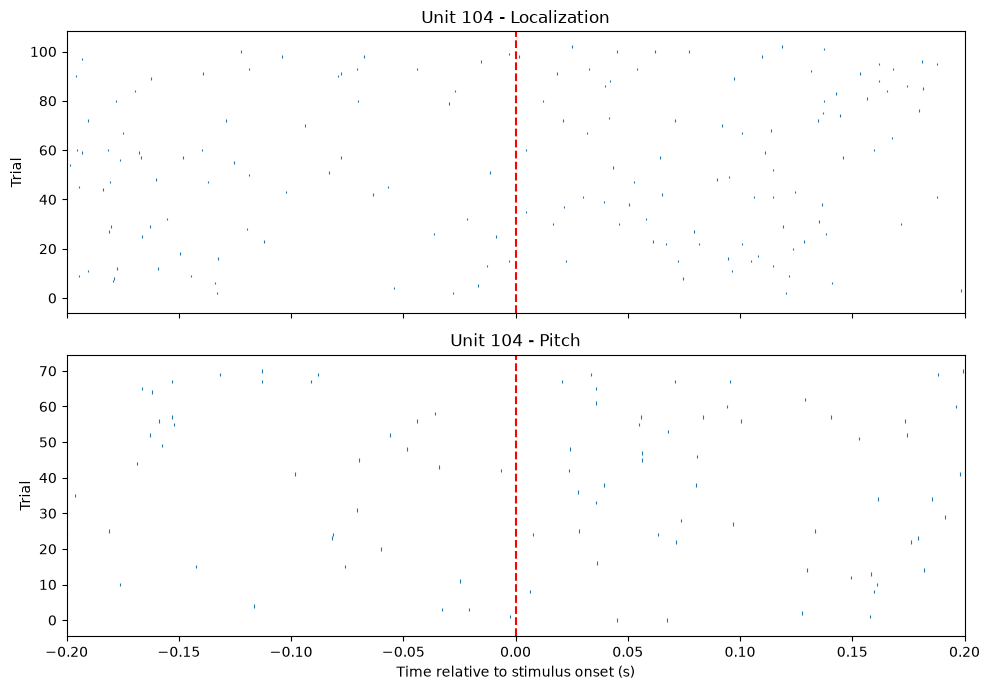

In [31]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True
)

for ax, data, label in zip(
    axes,
    [loc_aligned, pitch_aligned],
    ["Localization", "Pitch"]
):
    ax.eventplot(data, linewidths=0.8)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"Unit {selected_unit} - {label}")
    ax.set_ylabel("Trial")

axes[1].set_xlabel("Time relative to stimulus onset (s)")
axes[1].set_xlim(-0.2, 0.2)

plt.tight_layout()
plt.show()

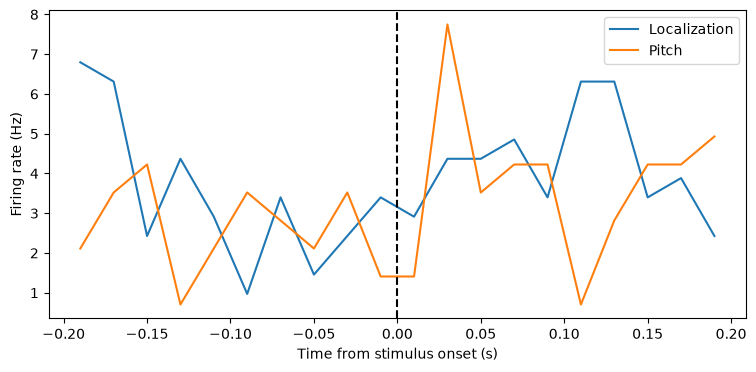

In [32]:
bins = np.linspace(-0.2, 0.2, 21)
bin_width = np.diff(bins)[0]

def compute_psth(aligned_spikes, bins):
    all_spikes = np.concatenate(aligned_spikes)

    counts, _ = np.histogram(all_spikes, bins=bins)

    firing_rate = counts / (len(aligned_spikes) * np.diff(bins))

    return firing_rate


loc_psth = compute_psth(loc_aligned, bins)
pitch_psth = compute_psth(pitch_aligned, bins)

bin_centers = (bins[:-1] + bins[1:]) / 2

plt.figure(figsize=(9, 4))

plt.plot(bin_centers, loc_psth, label="Localization")
plt.plot(bin_centers, pitch_psth, label="Pitch")

plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Time from stimulus onset (s)")
plt.ylabel("Firing rate (Hz)")
plt.legend()
plt.show()

In [33]:
correct_trials = correct_trials.sort_values("stim_onset")

onsets = correct_trials["stim_onset"].to_numpy()

units = np.sort(mpfc_spikes["unit"].unique())

unit_spikes = {
    u: np.sort(g["time"].to_numpy())
    for u, g in mpfc_spikes.groupby("unit")
}

X_pre = np.column_stack([
    (
        np.searchsorted(unit_spikes[u], onsets)
        -
        np.searchsorted(unit_spikes[u], onsets - 0.2)
    ) / 0.2
    for u in units
])

y = (correct_trials["rule"] == "Pitch").astype(int).to_numpy()

print("Population matrix:", X_pre.shape)
print("Rule labels:", y.shape)
print("NaN values:", np.isnan(X_pre).sum())

assert X_pre.shape == (174, 42)

Population matrix: (174, 42)
Rule labels: (174,)
NaN values: 0


In [34]:
activity_summary = pd.DataFrame({
    "unit": units,
    "active_trials": (X_pre > 0).sum(axis=0),
    "mean_firing_rate": X_pre.mean(axis=0)
})

display(
    activity_summary.sort_values(
        "active_trials",
        ascending=False
    )
)

print("Zero entries (%):", 100 * np.mean(X_pre == 0))

,unit,active_trials,mean_firing_rate
22,206,86,3.620690
3,104,78,3.103448
25,209,75,3.563218
18,202,71,2.557471
24,208,52,1.839080
23,207,45,1.695402
19,203,35,1.235632
6,107,24,1.264368
28,212,23,0.919540
15,116,15,0.689655


Zero entries (%): 92.32348111658456


In [35]:
import numpy as np
import pandas as pd

assert X_pre.shape == (174, 42)
assert len(correct_trials) == X_pre.shape[0]

active_trials = (X_pre > 0).sum(axis=0)
mean_rates = X_pre.mean(axis=0)

qc = pd.DataFrame({
    "unit": units,
    "active_trials": active_trials,
    "mean_FR": mean_rates
})

print("Sparsity (%):", 100 * np.mean(X_pre == 0))
print("Completely silent units:", np.sum(active_trials == 0))
print("Units active in >= 5 trials:", np.sum(active_trials >= 5))

display(qc.sort_values("active_trials", ascending=False))

Sparsity (%): 92.32348111658456
Completely silent units: 17
Units active in >= 5 trials: 14


,unit,active_trials,mean_FR
22,206,86,3.620690
3,104,78,3.103448
25,209,75,3.563218
18,202,71,2.557471
24,208,52,1.839080
23,207,45,1.695402
19,203,35,1.235632
6,107,24,1.264368
28,212,23,0.919540
15,116,15,0.689655


In [36]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

y = (correct_trials["rule"] == "Pitch").astype(int).to_numpy()

p_values = np.full(X_pre.shape[1], np.nan)

for j in range(X_pre.shape[1]):

    loc = X_pre[y == 0, j]
    pitch = X_pre[y == 1, j]

    if np.var(X_pre[:, j]) > 0:
        p_values[j] = mannwhitneyu(
            loc, pitch, alternative="two-sided"
        ).pvalue

valid_p = np.isfinite(p_values)

q_values = np.full_like(p_values, np.nan)

q_values[valid_p] = multipletests(
    p_values[valid_p],
    method="fdr_bh"
)[1]

selectivity_df = pd.DataFrame({
    "unit": units,
    "FR_loc": X_pre[y == 0].mean(axis=0),
    "FR_pitch": X_pre[y == 1].mean(axis=0),
    "p_value": p_values,
    "q_value": q_values
})

display(selectivity_df.sort_values("p_value").head(10))

,unit,FR_loc,FR_pitch,p_value,q_value
15,116,1.116505,0.070423,0.004773,0.119335
28,212,0.582524,1.408451,0.012237,0.124692
20,204,0.145631,0.563380,0.014963,0.124692
23,207,1.456311,2.042254,0.063781,0.398632
11,112,0.000000,0.140845,0.089130,0.445651
14,115,0.145631,0.000000,0.149971,0.535609
8,109,0.145631,0.000000,0.149971,0.535609
3,104,3.446602,2.605634,0.231131,0.550687
32,304,0.000000,0.070423,0.232964,0.550687
16,117,0.000000,0.070423,0.232964,0.550687


In [37]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

y = (correct_trials["rule"] == "Pitch").astype(int).to_numpy()

p_values = np.full(X_pre.shape[1], np.nan)

for j in range(X_pre.shape[1]):

    loc = X_pre[y == 0, j]
    pitch = X_pre[y == 1, j]

    if np.var(X_pre[:, j]) > 0:
        p_values[j] = mannwhitneyu(
            loc, pitch, alternative="two-sided"
        ).pvalue

valid_p = np.isfinite(p_values)

q_values = np.full_like(p_values, np.nan)

q_values[valid_p] = multipletests(
    p_values[valid_p],
    method="fdr_bh"
)[1]

selectivity_df = pd.DataFrame({
    "unit": units,
    "FR_loc": X_pre[y == 0].mean(axis=0),
    "FR_pitch": X_pre[y == 1].mean(axis=0),
    "p_value": p_values,
    "q_value": q_values
})

display(selectivity_df.sort_values("p_value").head(10))

,unit,FR_loc,FR_pitch,p_value,q_value
15,116,1.116505,0.070423,0.004773,0.119335
28,212,0.582524,1.408451,0.012237,0.124692
20,204,0.145631,0.563380,0.014963,0.124692
23,207,1.456311,2.042254,0.063781,0.398632
11,112,0.000000,0.140845,0.089130,0.445651
14,115,0.145631,0.000000,0.149971,0.535609
8,109,0.145631,0.000000,0.149971,0.535609
3,104,3.446602,2.605634,0.231131,0.550687
32,304,0.000000,0.070423,0.232964,0.550687
16,117,0.000000,0.070423,0.232964,0.550687


In [38]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score
)
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    roc_auc_score
)

trial_numbers = correct_trials.index.to_numpy(dtype=int)

cycles = (trial_numbers - 1) // 160

print("First trial numbers:", trial_numbers[:10])
print("Cycle counts:")
print(pd.Series(cycles).value_counts().sort_index())

assert len(trial_numbers) == X_pre.shape[0]
assert correct_trials["stim_onset"].is_monotonic_increasing

mask = cycles < 2

X_cv = X_pre[mask]
y_cv = y[mask]
groups = cycles[mask]

model = Pipeline([
    ("variance", VarianceThreshold()),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

cv = LeaveOneGroupOut()

predictions = np.zeros(len(y_cv), dtype=int)
probabilities = np.zeros(len(y_cv))

for train_idx, test_idx in cv.split(X_cv, y_cv, groups):

    model.fit(X_cv[train_idx], y_cv[train_idx])

    predictions[test_idx] = model.predict(X_cv[test_idx])

    probabilities[test_idx] = model.predict_proba(
        X_cv[test_idx]
    )[:, 1]

    print(
        "Held-out cycle:",
        groups[test_idx][0],
        "Balanced accuracy:",
        balanced_accuracy_score(
            y_cv[test_idx],
            predictions[test_idx]
        )
    )

print("Overall balanced accuracy:",
      balanced_accuracy_score(y_cv, predictions))

print("ROC AUC:",
      roc_auc_score(y_cv, probabilities))

print("Confusion matrix:")
print(confusion_matrix(y_cv, predictions))

First trial numbers: [21 22 26 27 28 29 30 31 32 34]
Cycle counts:
0    77
1    77
2    20
Name: count, dtype: int64
Held-out cycle: 0 Balanced accuracy: 0.4393939393939394
Held-out cycle: 1 Balanced accuracy: 0.4821187584345479
Overall balanced accuracy: 0.46538265739012386
ROC AUC: 0.493806210758527
Confusion matrix:
[[34 49]
 [34 37]]


In [39]:
trials_work = correct_trials.sort_values("stim_onset").copy()

onsets = trials_work["stim_onset"].to_numpy()
trial_numbers = trials_work.index.to_numpy(dtype=int)

y = (trials_work["rule"] == "Pitch").astype(int).to_numpy()
cycles = (trial_numbers - 1) // 160

cv_mask = cycles < 2

print(pd.crosstab(cycles, trials_work["rule"]))

assert len(onsets) == X_pre.shape[0]
assert trials_work["stim_onset"].is_monotonic_increasing
assert set(np.unique(y[cv_mask])) == {0, 1}

rule   Localization  Pitch
row_0                     
0                44     33
1                39     38
2                20      0


In [40]:
windows = {
    "Pre early":   (-0.20, -0.10),
    "Pre late":    (-0.10,  0.00),
    "Pre 200":     (-0.20,  0.00),
    "Post early":  ( 0.00,  0.10),
    "Post late":   ( 0.10,  0.20),
    "Post 200":    ( 0.00,  0.20),
}

spike_by_unit = {
    u: np.sort(group["time"].to_numpy())
    for u, group in mpfc_spikes.groupby("unit")
}

def build_population_features(t_start, t_end):

    duration = t_end - t_start
    columns = []

    for unit in units:
        times = spike_by_unit[unit]

        left = np.searchsorted(times, onsets + t_start)
        right = np.searchsorted(times, onsets + t_end)

        rates = (right - left) / duration
        columns.append(rates)

    return np.column_stack(columns)


X_windows = {
    name: build_population_features(start, end)
    for name, (start, end) in windows.items()
}

for name, X in X_windows.items():
    print(name, X.shape, "Sparsity:", round(np.mean(X == 0), 3))

print("Original pre matrix matches:",
      np.allclose(X_windows["Pre 200"], X_pre))

Pre early (174, 42) Sparsity: 0.951
Pre late (174, 42) Sparsity: 0.958
Pre 200 (174, 42) Sparsity: 0.923
Post early (174, 42) Sparsity: 0.959
Post late (174, 42) Sparsity: 0.955
Post 200 (174, 42) Sparsity: 0.925
Original pre matrix matches: True


In [41]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

def evaluate_window(X):

    X_testable = X[cv_mask]
    y_testable = y[cv_mask]
    groups = cycles[cv_mask]

    predictions = np.zeros(len(y_testable), dtype=int)
    probabilities = np.zeros(len(y_testable))

    fold_scores = []

    for train, test in LeaveOneGroupOut().split(
        X_testable, y_testable, groups
    ):

        model = Pipeline([
            ("variance", VarianceThreshold()),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                max_iter=2000,
                class_weight="balanced"
            ))
        ])

        model.fit(X_testable[train], y_testable[train])

        predictions[test] = model.predict(X_testable[test])
        probabilities[test] = model.predict_proba(
            X_testable[test]
        )[:, 1]

        fold_scores.append(
            balanced_accuracy_score(
                y_testable[test], predictions[test]
            )
        )

    return {
        "Balanced Accuracy": balanced_accuracy_score(
            y_testable, predictions
        ),
        "ROC AUC": roc_auc_score(
            y_testable, probabilities
        ),
        "Cycle 0": fold_scores[0],
        "Cycle 1": fold_scores[1]
    }


results = pd.DataFrame([
    {"Window": name, **evaluate_window(X)}
    for name, X in X_windows.items()
])

display(results.round(3))

,Window,Balanced Accuracy,ROC AUC,Cycle 0,Cycle 1
0,Pre early,0.567,0.592,0.527,0.611
1,Pre late,0.495,0.511,0.527,0.445
2,Pre 200,0.465,0.494,0.439,0.482
3,Post early,0.321,0.295,0.398,0.235
4,Post late,0.558,0.572,0.530,0.574
5,Post 200,0.396,0.393,0.443,0.352


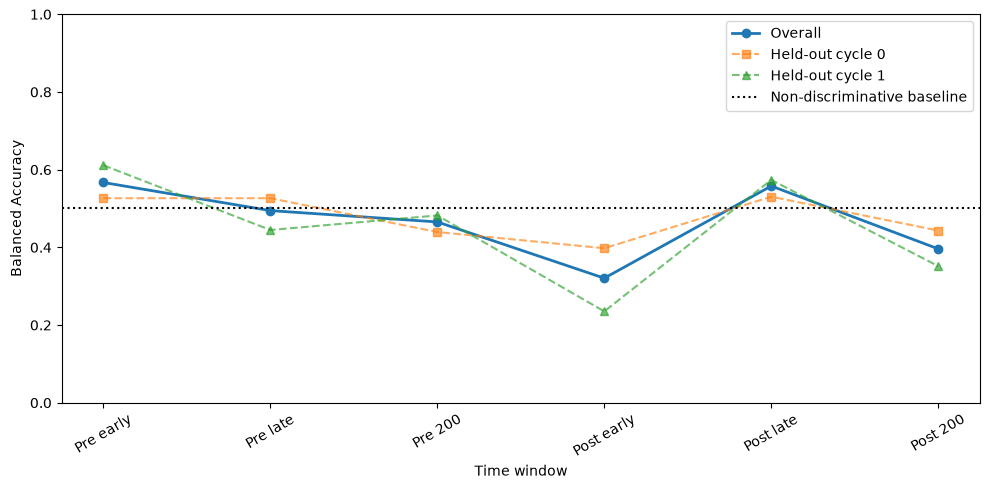

In [43]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    results["Window"],
    results["Balanced Accuracy"],
    marker="o",
    linewidth=2,
    label="Overall"
)

ax.plot(
    results["Window"],
    results["Cycle 0"],
    marker="s",
    linestyle="--",
    alpha=0.65,
    label="Held-out cycle 0"
)

ax.plot(
    results["Window"],
    results["Cycle 1"],
    marker="^",
    linestyle="--",
    alpha=0.65,
    label="Held-out cycle 1"
)

ax.axhline(0.5, linestyle=":", color="black",
           label="Non-discriminative baseline")

ax.set_ylabel("Balanced Accuracy")
ax.set_xlabel("Time window")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=30)
ax.legend()

plt.tight_layout()
plt.savefig("temporal_decoding.png", dpi=300)
plt.show()

In [44]:
trials_work["stim_identity"] = trials_work[
    "stim_name"
].str.extract(r"^((?:le|ri)_(?:hi|lo))_", expand=False)

assert trials_work["stim_identity"].notna().all()

print("Stimulus distribution by rule:")
display(
    pd.crosstab(
        trials_work["rule"],
        trials_work["stim_identity"],
        normalize="index"
    ).round(3)
)

print("Go / No-go distribution:")
display(
    pd.crosstab(
        trials_work["rule"],
        trials_work["go_or_nogo"],
        normalize="index"
    ).round(3)
)

Stimulus distribution by rule:


stim_identity,le_hi,le_lo,ri_hi,ri_lo
rule,,,,
Localization,0.359,0.243,0.243,0.155
Pitch,0.197,0.239,0.169,0.394


Go / No-go distribution:


go_or_nogo,go,nogo
rule,,
Localization,0.602,0.398
Pitch,0.634,0.366


In [45]:
trials_work["exit_latency"] = (
    trials_work["cpoke_stop"] -
    trials_work["stim_onset"]
)

trials_work["pre_hold"] = (
    trials_work["stim_onset"] -
    trials_work["cpoke_start"]
)

display(
    trials_work.groupby("rule")[
        ["pre_hold", "exit_latency"]
    ].agg(["min", "median", "max"]).round(3)
)

print("Proportion exiting before 100 ms:")
display(
    pd.crosstab(
        trials_work["rule"],
        trials_work["exit_latency"] < 0.1,
        normalize="index"
    ).round(3)
)

pre_hold               exit_latency              
                  min median    max          min median    max
rule                                                          
Localization    0.250  0.301  0.349        0.001  0.104  0.249
Pitch           0.251  0.298  0.348        0.007  0.133  0.249

Proportion exiting before 100 ms:


exit_latency,False,True
rule,,
Localization,0.524,0.476
Pitch,0.676,0.324


In [46]:
from sklearn.preprocessing import OneHotEncoder

X_stim = trials_work[["stim_identity"]].to_numpy()[cv_mask]
y_cv = y[cv_mask]
groups_cv = cycles[cv_mask]

stim_pred = np.zeros(len(y_cv), dtype=int)

for train, test in LeaveOneGroupOut().split(
    X_stim, y_cv, groups_cv
):
    baseline = Pipeline([
        ("encoding", OneHotEncoder(handle_unknown="ignore")),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=2000
        ))
    ])

    baseline.fit(X_stim[train], y_cv[train])
    stim_pred[test] = baseline.predict(X_stim[test])

print(
    "Stimulus-only balanced accuracy:",
    balanced_accuracy_score(y_cv, stim_pred)
)

Stimulus-only balanced accuracy: 0.5728830816222636


In [47]:
phase = (trial_numbers - 1) % 160

phase_prediction = (phase >= 100).astype(int)

print(
    "Rule prediction using task phase:",
    np.mean(phase_prediction[cv_mask] == y[cv_mask])
)

Rule prediction using task phase: 1.0


In [ ]:
# PCA: each trial = 25 nonconstant firing-rate features (154 trials)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_pca = X_pre[cv_mask]
y_pca = y[cv_mask]
cycle_pca = cycles[cv_mask]
nonconstant_units = X_pca.var(axis=0) > 0
X_active = X_pca[:, nonconstant_units]
active_unit_ids = units[nonconstant_units]

X_scaled = StandardScaler().fit_transform(X_active)
pca = PCA(n_components=2)
Z = pca.fit_transform(X_scaled)

print('Trials:', len(X_pca))
print('Nonconstant units:', len(active_unit_ids))
print('PCA scores:', Z.shape)
print('Explained variance PC1/PC2:', pca.explained_variance_ratio_)
print('Total explained variance:', pca.explained_variance_ratio_.sum())


In [ ]:
# Two views of exactly the same PCA coordinates: Rule vs. Cycle
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for label, name in [(0, 'Localization'), (1, 'Pitch')]:
    take = y_pca == label
    axes[0].scatter(Z[take, 0], Z[take, 1], alpha=0.7, label=name)
axes[0].set_title('PCA — Task Rule')
axes[0].legend()

for cycle_id in np.unique(cycle_pca):
    take = cycle_pca == cycle_id
    axes[1].scatter(Z[take, 0], Z[take, 1], alpha=0.7, label=f'Cycle {cycle_id}')
axes[1].set_title('PCA — Experimental Cycle')
axes[1].legend()
for ax in axes:
    ax.set_xlabel(f'PC1 ({100*pca.explained_variance_ratio_[0]:.2f}%)')
    ax.set_ylabel(f'PC2 ({100*pca.explained_variance_ratio_[1]:.2f}%)')
plt.tight_layout()
plt.savefig('pca_rule_vs_cycle.png', dpi=300, bbox_inches='tight')
plt.show()
# PCA is descriptive, not evidence of rule-specific encoding.


In [ ]:
# Matched control: physical stimulus and REQUIRED response, within each cycle
candidates = trials_work.iloc[np.flatnonzero(cv_mask)].copy()
candidates['cycle'] = cycles[cv_mask]
candidates['row_in_X'] = np.flatnonzero(cv_mask)
candidates = candidates.loc[
    candidates['stim_identity'].isin(['le_lo', 'ri_hi'])
].copy()

print('Required responses:')
display(pd.crosstab(candidates['stim_identity'],
                    [candidates['rule'], candidates['go_or_nogo']]))
print('Candidate counts:')
display(pd.crosstab([candidates['cycle'], candidates['rule']],
                    candidates['stim_identity']))
print('Total candidates:', len(candidates))
assert len(candidates) == 70


In [ ]:
# Random, reproducible subsampling within Cycle x Stimulus x Rule
rng = np.random.default_rng(42)
selected_rows = []
for (cycle_id, stimulus), group in candidates.groupby(['cycle', 'stim_identity'], sort=True):
    loc_rows = group.loc[group['rule'] == 'Localization', 'row_in_X'].to_numpy(dtype=int)
    pitch_rows = group.loc[group['rule'] == 'Pitch', 'row_in_X'].to_numpy(dtype=int)
    n_match = min(len(loc_rows), len(pitch_rows))
    assert n_match > 0
    selected_rows.extend(rng.choice(loc_rows, size=n_match, replace=False))
    selected_rows.extend(rng.choice(pitch_rows, size=n_match, replace=False))

matched_rows = np.sort(np.asarray(selected_rows, dtype=int))
matched_trials = trials_work.iloc[matched_rows].copy()
matched_trials['cycle'] = cycles[matched_rows]
X_matched = X_pre[matched_rows]
y_matched = y[matched_rows]
groups_matched = cycles[matched_rows]

assert X_matched.shape == (58, 42)
assert np.array_equal(matched_trials.index.to_numpy(dtype=int), trial_numbers[matched_rows])
assert np.array_equal(y_matched, (matched_trials['rule'] == 'Pitch').astype(int).to_numpy())
assert np.unique(y_matched, return_counts=True)[1].tolist() == [29, 29]
matched_counts = pd.crosstab([matched_trials['cycle'], matched_trials['stim_identity']],
                             matched_trials['rule'])
assert (matched_counts['Localization'] == matched_counts['Pitch']).all()
display(matched_counts)
print('X_matched:', X_matched.shape)
print('Labels:', np.bincount(y_matched))


In [ ]:
# Same Logistic Regression pipeline and Leave-One-Cycle-Out as before
logo = LeaveOneGroupOut()
predictions_matched = np.zeros(len(y_matched), dtype=int)
probabilities_matched = np.zeros(len(y_matched))
fold_results = []
for train_idx, test_idx in logo.split(X_matched, y_matched, groups_matched):
    matched_model = Pipeline([
        ('variance', VarianceThreshold()),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            max_iter=2000, class_weight='balanced', random_state=42
        ))
    ])
    matched_model.fit(X_matched[train_idx], y_matched[train_idx])
    predictions_matched[test_idx] = matched_model.predict(X_matched[test_idx])
    probabilities_matched[test_idx] = matched_model.predict_proba(X_matched[test_idx])[:, 1]
    fold_results.append({
        'Held-out cycle': int(groups_matched[test_idx][0]),
        'Test trials': len(test_idx),
        'Balanced Accuracy': balanced_accuracy_score(y_matched[test_idx], predictions_matched[test_idx]),
        'ROC AUC': roc_auc_score(y_matched[test_idx], probabilities_matched[test_idx])
    })

display(pd.DataFrame(fold_results).round(3))
matched_ba = balanced_accuracy_score(y_matched, predictions_matched)
print('Matched Balanced Accuracy:', matched_ba)
print('Confusion matrix:\n', confusion_matrix(y_matched, predictions_matched))
print('Original Balanced Accuracy: 0.4654 (154 trials)')
print('Matched Balanced Accuracy:', round(matched_ba, 4), '(58 trials)')
# Caution: sample-size/composition changes; task rule remains temporally confounded.
